# Lesson 24 - Merging classes, answering per ship, and PANN embeddings, with "other" kept

Lessons 16 and 20 merged cargo with tanker (5 classes) and then fishing with tug (4 classes), and reached 78.9 % and
86.8 % per ship. **Without "other".** Here every grouping keeps it (lesson 22):

| Grouping | Classes |
|---|---|
| 6 classes + other | background, cargo, fishing, pleasure craft, tanker, tug, other |
| 5 classes + other | background, **cargo + tanker**, fishing, pleasure craft, tug, other |
| 4 classes + other | background, cargo + tanker, **fishing + tug**, pleasure craft, other |

The feature set is the one chosen in lesson 22 on validation (gradient boosting: the best mean validation score;
among sets within half a point, the one with the fewest numbers). Both models, and their probabilities averaged.
Per ship = the probabilities of all a ship's clips averaged into one answer (background: per recording day).

Then **PANN embeddings** (CNN14 pretrained on AudioSet, 2,048 numbers per clip reduced to 256 by PCA fitted on the
training + validation clips, lesson 21), alone and next to the chosen set, on 6 classes + other.

```
python src/with_other.py merged        # -> runs/with_other/merged.jsonl, merged_predictions.parquet (CPU)
```

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix
import six_classes as S
import with_other as W

OUT = W.OUT_DIR
res = pd.DataFrame(W.Log(OUT / "merged.jsonl").rows)
preds = pd.read_parquet(OUT / "merged_predictions.parquet")
pd.set_option("display.width", 170)
chosen = res[~res.features.str.startswith("PANN")].features.iloc[0]
print(f"feature set: {chosen}")


def pm(v):
    return f"{100 * np.mean(v):.1f} ± {100 * np.std(v, ddof=1):.1f}"


def per_ship(probs, y, ships):
    return S.per_ship_balanced_accuracy(probs, y, ships)


def scores_of(p, names):
    """per fold: (per clip, per ship) balanced accuracy of the probabilities in p"""
    out = []
    for k, f in p.groupby("fold"):
        pr = f[[f"p_{n}" for n in names]].to_numpy()
        out.append((balanced_accuracy_score(f.y, pr.argmax(1)), per_ship(pr, f.y.to_numpy(), f.ship.to_numpy())))
    return np.array(out)

feature set: engineered + mel mean + spread (401)


## 1. Merged classes, with "other"

In [2]:
rows = []
for grouping, names in W.GROUPINGS.items():
    names = list(names)
    sub = preds[(preds.grouping == grouping) & (preds.features == chosen)]
    for model in ("logistic regression", "gradient boosting", "both averaged"):
        if model == "both averaged":
            a = sub[sub.model == "logistic regression"].sort_values(["fold", "row"]).reset_index(drop=True)
            b = sub[sub.model == "gradient boosting"].sort_values(["fold", "row"]).reset_index(drop=True)
            p = a.copy()
            p[[f"p_{n}" for n in names]] = (a[[f"p_{n}" for n in names]].to_numpy() + b[[f"p_{n}" for n in names]].to_numpy()) / 2
        else:
            p = sub[sub.model == model]
        s = scores_of(p, names)
        other = np.mean([(f[[f"p_{n}" for n in names]].to_numpy().argmax(1) == names.index("other"))[f.y == names.index("other")].mean()
                         for _, f in p.groupby("fold")])
        rows.append({"grouping": grouping, "model": model, "per clip": pm(s[:, 0]), "per ship": pm(s[:, 1]),
                     "other recall (clip)": round(100 * other, 1)})
merged_table = pd.DataFrame(rows).set_index(["grouping", "model"])
print("test, balanced accuracy, mean ± spread of 5 folds")
print(merged_table.to_string())

test, balanced accuracy, mean ± spread of 5 folds
                                         per clip    per ship  other recall (clip)
grouping          model                                                           
6 classes + other logistic regression  52.5 ± 0.8  59.0 ± 1.0                 17.7
                  gradient boosting    56.2 ± 0.4  65.0 ± 2.6                 32.9
                  both averaged        56.9 ± 0.7  63.5 ± 2.5                 27.4
5 classes + other logistic regression  57.4 ± 1.4  63.5 ± 2.0                 18.1
                  gradient boosting    62.6 ± 0.8  71.2 ± 3.4                 35.9
                  both averaged        62.2 ± 1.0  68.8 ± 2.3                 28.9
4 classes + other logistic regression  63.9 ± 1.0  69.2 ± 1.0                 23.2
                  gradient boosting    69.5 ± 1.0  76.3 ± 1.0                 40.7
                  both averaged        68.8 ± 0.9  74.2 ± 0.3                 34.3


Without "other", for comparison (lessons 16, 20; gradient boosting, engineered): 6 classes 61.9 / 70.5 %, 5 classes
69.9 / 78.9 %, 4 classes 80.2 / 86.8 % (per clip / per ship).

- **Merging still adds 6-7 points per step, with "other" kept:** gradient boosting 56.2 → 62.6 → 69.5 % per clip and
  65.0 → 71.2 → 76.3 % per ship for 6, 5 and 4 classes + other.
- **4 classes + other reaches the 75 % goal per ship (76.3 ± 1.0 %).** It is the only grouping that does with "other"
  kept; 5 classes + other stays at 71.2 %. Per clip no grouping gets there (69.5 % at best).
- **"Other" costs more the coarser the question:** 5.7 points per clip with 6 classes, 7.3 with 5, 10.7 with 4. With
  fewer, larger named classes, "other" is a bigger share of what is left to get wrong: it is still recognised only
  33-41 % of the time (a little more as the named classes merge).
- **The merged classes themselves hold up:** cargo + tanker right 94.6-94.8 % (96 % without "other"), fishing + tug
  67.2 % (73.5 %), pleasure craft about 60 % (64-66 %). They lose a few points to "other".
- **Logistic regression is 5-6 points behind gradient boosting** in every grouping. Averaging the two models'
  probabilities does not help: within a point per clip, and 1.5-2.4 points lower per ship.

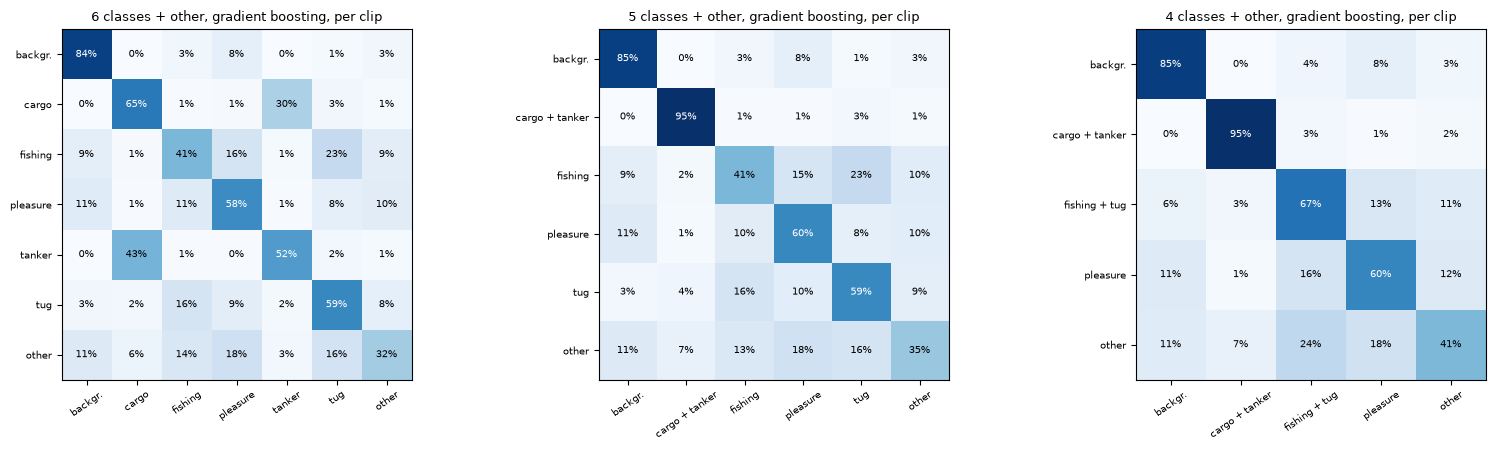

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, (grouping, names) in zip(axes, W.GROUPINGS.items()):
    names = list(names)
    p = preds[(preds.grouping == grouping) & (preds.features == chosen) & (preds.model == "gradient boosting")]
    cm = confusion_matrix(p.y, p[[f"p_{n}" for n in names]].to_numpy().argmax(1), labels=range(len(names)), normalize="true")
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=0.9)
    for i in range(len(names)):
        for j in range(len(names)):
            ax.text(j, i, f"{cm[i, j]:.0%}", ha="center", va="center", fontsize=7, color="white" if cm[i, j] > 0.5 else "black")
    short = [n.replace("pleasurecraft", "pleasure").replace("background", "backgr.") for n in names]
    ax.set_xticks(range(len(names)), short, rotation=35, fontsize=7); ax.set_yticks(range(len(names)), short, fontsize=7)
    ax.set_title(f"{grouping}, gradient boosting, per clip", fontsize=9)
plt.tight_layout(); plt.show()

## 2. Merging after training gives the same answer

Lesson 16 found that training on merged classes = adding the six-class model's probabilities afterwards. Checked
again with "other": the 6 + other model's probabilities are added up into the 5 + other and 4 + other classes.

In [4]:
six = preds[(preds.grouping == W.MAIN) & (preds.features == chosen) & (preds.model == "gradient boosting")]
names6 = list(W.GROUPINGS[W.MAIN])
rows = []
for grouping in ("5 classes + other", "4 classes + other"):
    target = W.GROUPINGS[grouping]
    names = list(target)
    index = {l: i for i, m in enumerate(target.values()) for l in m}
    six_to = {i6: index[n6] if n6 != "other" else names.index("other") for i6, n6 in enumerate(names6)}
    p = six[["fold", "ship"]].copy()
    for j, n in enumerate(names):
        p[f"p_{n}"] = six[[f"p_{n6}" for i6, n6 in enumerate(names6) if six_to[i6] == j]].sum(axis=1)
    p["y"] = six.y.map(six_to)
    s = scores_of(p, names)
    rows.append({"grouping": grouping, "6 + other model, added afterwards": f"{pm(s[:, 0])} / {pm(s[:, 1])}",
                 "trained on the grouping": f"{merged_table.loc[(grouping, 'gradient boosting'), 'per clip']} / "
                                            f"{merged_table.loc[(grouping, 'gradient boosting'), 'per ship']}"})
print("per clip / per ship (%)")
print(pd.DataFrame(rows).set_index("grouping").to_string())

per clip / per ship (%)
                  6 + other model, added afterwards  trained on the grouping
grouping                                                                    
5 classes + other           61.8 ± 0.4 / 70.0 ± 2.3  62.6 ± 0.8 / 71.2 ± 3.4
4 classes + other           67.4 ± 0.9 / 71.9 ± 2.7  69.5 ± 1.0 / 76.3 ± 1.0


- **With "other", training on the grouping is better than merging afterwards:** 5 classes + other 62.6 / 71.2 %
  against 61.8 / 70.0 %, 4 classes + other 69.5 / 76.3 % against 67.4 / 71.9 % (per clip / per ship). Lesson 16 had
  found the two the same, but there the weights did not change with the grouping. Here each merged class gets the
  same total weight as "other" and the other classes, so the model trained on the grouping learns that balance;
  the six-class model gives cargo + tanker twice the weight of a class.

## 3. Answering only when sure

A system can say "not sure" for a ship whose averaged probability is low. Sorting the test ships by their highest
averaged probability and keeping the most confident share shows the trade-off (gradient boosting, per ship). Scored
as the share of answered ships named correctly, each ship weighted by 1 / (ships of its class in the test fold), so
every class counts the same (2,522 cargo ships would otherwise decide it). The weights are fixed on all test ships:
recomputing balanced accuracy on the answered subset alone is misleading, since hard classes keep only a few ships.

6 classes + other: all ships 65.0 %, most confident 80 % 71.9 %, 60 % 76.1 %


5 classes + other: all ships 71.2 %, most confident 80 % 82.1 %, 60 % 93.5 %


4 classes + other: all ships 76.3 %, most confident 80 % 86.0 %, 60 % 94.9 %


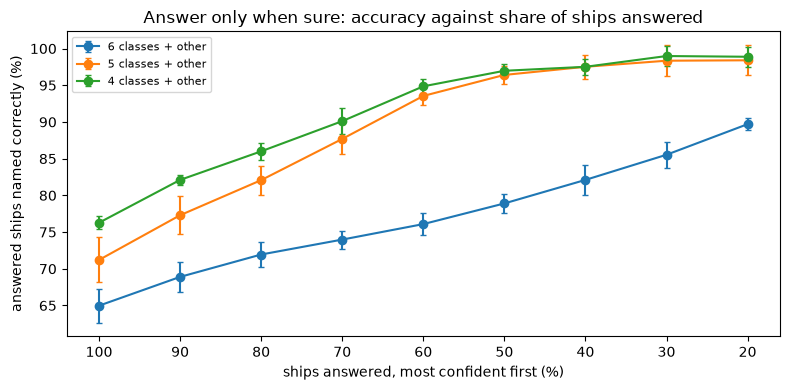

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
for grouping, names in W.GROUPINGS.items():
    names = list(names)
    p = preds[(preds.grouping == grouping) & (preds.features == chosen) & (preds.model == "gradient boosting")]
    curve = []
    for k, f in p.groupby("fold"):
        per = f.groupby("ship")[[f"p_{n}" for n in names] + ["y"]].mean()
        pr = per[[f"p_{n}" for n in names]].to_numpy()
        conf, pred, y = pr.max(axis=1), pr.argmax(axis=1), per.y.to_numpy().astype(int)
        w = 1.0 / np.bincount(y, minlength=len(names))[y]                  # every class the same total weight
        o = np.argsort(-conf)
        keep = [o[:max(20, int(c * len(o)))] for c in np.linspace(0.2, 1, 9)]
        curve.append([accuracy_score(y[k], pred[k], sample_weight=w[k]) for k in keep])
    curve = 100 * np.array(curve)
    ax.errorbar(100 * np.linspace(0.2, 1, 9), curve.mean(0), yerr=curve.std(0), marker="o", capsize=2, label=grouping)
    print(f"{grouping}: all ships {curve[:, -1].mean():.1f} %, most confident 80 % {curve[:, -3].mean():.1f} %, "
          f"60 % {curve[:, -5].mean():.1f} %")
ax.set_xlabel("ships answered, most confident first (%)"); ax.set_ylabel("answered ships named correctly (%)")
ax.invert_xaxis(); ax.legend(fontsize=8); ax.set_title("Answer only when sure: accuracy against share of ships answered")
plt.tight_layout(); plt.show()

- **Answering only when sure raises the score, at a price.** With 80 % of ships answered: 6 classes + other 71.9 %
  (65.0 % for all), 5 classes + other 82.1 % (71.2 %), 4 classes + other 86.0 % (76.3 %).
- **The ships set aside are mostly the hard ones.** For 5 classes + other at 80 % answered: 63 % of fishing boats,
  58 % of "other" ships and 46 % of tugs and pleasure craft go unanswered, against 5 % of cargo ships and tankers and
  12 % of background days. So "not sure" here mostly means "a small boat, or a type we don't name", which is useful
  to report but is not a better recogniser.

## 4. PANN embeddings, with "other"

In [6]:
pann = res[(res.grouping == W.MAIN)]
g = pann.groupby(["features", "model"], sort=False)
print(pd.DataFrame({"numbers": g.n_features.first(),
                    "per clip": g.balanced_accuracy.apply(pm), "per ship": g.per_ship_balanced_accuracy.apply(pm)}).to_string())
print(f"\nvariance kept by 256 PCA components: {pann.pca_variance.dropna().mean():.1%}")
for m in ("gradient boosting", "logistic regression"):
    x = pann[pann.model == m].pivot(index="fold", columns="features", values="per_ship_balanced_accuracy")
    both = [c for c in x.columns if c.startswith("PANN (256) + ")][0]
    print(f"{m}: PANN + set minus set, per ship, by fold: {(100 * (x[both] - x[chosen])).round(1).tolist()}")

                                                                       numbers    per clip    per ship
features                                          model                                               
engineered + mel mean + spread (401)              logistic regression      401  52.5 ± 0.8  59.0 ± 1.0
                                                  gradient boosting        401  56.2 ± 0.4  65.0 ± 2.6
PANN (256)                                        logistic regression      256  45.5 ± 0.8  53.8 ± 1.6
                                                  gradient boosting        256  44.3 ± 0.8  54.4 ± 1.0
PANN (256) + engineered + mel mean + spread (401) logistic regression      657  52.5 ± 0.6  60.4 ± 0.9
                                                  gradient boosting        657  56.5 ± 0.6  65.3 ± 2.4

variance kept by 256 PCA components: 98.8%
gradient boosting: PANN + set minus set, per ship, by fold: [2.3, 0.1, 0.4, 0.1, -1.2]
logistic regression: PANN + set minus set, pe

- **PANN embeddings alone are far below our features with "other":** 44.3 % per clip, 54.4 % per ship (gradient
  boosting) against 56.2 / 65.0 % for the 401 numbers. They describe sound in air (AudioSet); "other" is recognised
  only 15 % of the time with them.
- **Added to the 401 numbers they change little:** gradient boosting 56.5 / 65.3 % (+0.3 / +0.3; per ship by fold
  +2.3, +0.1, +0.4, +0.1, -1.2), logistic regression 52.5 / 60.4 % (+0.0 / +1.4, better on every fold per ship). As in
  lesson 21, not worth a GPU pass over the audio and 256 more numbers.

## 5. What else could raise the accuracy

Tested in lessons 13-24 and kept: ship weights instead of deleting data (lesson 14), per-ship answers (+7-9 points),
engineered + mel statistics in one model (lesson 22), merging classes that sound alike (+6-7 points per merge).
Tested and dropped: removing high mel bands (15, 23), class offsets and larger trees for fishing (19), an SVM (20),
averaging two models (24), PANN embeddings (21, 24), EfficientNet on mel + features (17).

Not tried yet, in the order we would try them:

| Idea | Why it might help | Cost |
|---|---|---|
| Decide per passage, with the ship's distance and speed | per ship already adds 7-9 points; distance and speed (lesson 18) say how loud a ship should be | small: classical models on clip summaries |
| A two-step decision: ship or no ship, then big or small, then the type | background is right 84 %, cargo + tanker 95 %; the errors are among small boats and "other" | small |
| Report "not sure" per ship (section 3) | 82 % on the ships answered (5 + other) | none; the threshold is chosen for the use |
| More different ships per class, not more hours | the dataset's paper: doubling ships +2.4-2.6 points, doubling hours +0.8-1.3 | needs new recordings |
| Weight "other" differently | trades "other" recall against the named classes | small; must be chosen on validation |

## 6. What it means

| Gradient boosting, engineered + mel mean + spread, 5 test folds | Per clip | Per ship |
|---|---|---|
| 6 classes + other | 56.2 % | 65.0 % |
| 5 classes + other (cargo + tanker) | 62.6 % | 71.2 % |
| **4 classes + other (+ fishing + tug)** | **69.5 %** | **76.3 %** |
| 5 classes + other, the 80 % most confident ships | | 82.1 % |
| 6 classes + other, PANN + the 401 numbers | 56.5 % | 65.3 % |

- With "other" kept, the 75 % goal is reached only per ship and only with 4 classes + other.
- Merging after training is no longer the same as training on the merged classes; train on the grouping chosen.
- PANN embeddings and model averaging don't help. What remains hard is "other" and the small boats: the ships a
  "not sure" answer sets aside.